# Multi-seed averaging of the original winning recipe

The user chose option 2: average 3–5 independently seeded fits of `submission_final_model_improvements.csv`, whose reported Kaggle score is **0.98629**. All model parameters, iteration budgets, text representations and within-member ensemble weights remain those of the original corrected-v3 nine-specialist recipe. The only experiment is arithmetic averaging across preselected random seeds.

All new source is in this notebook under `submissions/team-35/plum/`. Outputs go to `artifacts/best_recipe_seed_average/`. Prior notebooks, source/configuration files, input CSVs and the winning submission are preserved. No new pretrained weights, GPU setup, test fitting, pseudo-labels or Kaggle API calls.

Run from this notebook's directory. It reuses definition cells from `further_model_tuning.ipynb`, which load the original engine. Its audited artifacts and supplied CSVs must be available. No scripts or new packages are required.


## Plan and checks

1. Verify the original configuration, data hashes, audited 8,000/2,000 split and grouped folds. Keep the outer five development folds fixed at seed 42 for every member.
2. Test that optimized feature reuse reproduces the original dense matrices for a different seed, and that deterministic L-BFGS logistic predictions do not change with `random_state`.
3. Fit members 42, 43, 44, 45 and 46. In development fold k, use training seed member+k, matching the original seed-42 baseline exactly. All stochastic tree fits, inner word-LM folds and SVC calibration folds vary. The two deterministic logistic branches can be reused on identical data. Never reuse fitted validation-dependent features across outer partitions.
4. Compare the predeclared 3-seed and 5-seed arithmetic probability averages with the original single-seed recipe. Record original/stress AUROC, per-fold changes and prediction spread. Freeze these two equal-weight recipes before new holdout predictions; do not choose seeds or weights using the holdout or Kaggle scores.
5. Assess the fixed 2,000-row holdout and observable subgroups, then refit all members on the full 10,000 labels. Require seed 42 to reproduce the original CSV numerically. Export 3-seed and 5-seed CSVs with exact schema/IDs, finite probabilities, distinct rankings, hashes and an independent representative fit check.

The holdout has historical exposure, and its rare-genre coverage is poor. Local differences are not a guarantee of leaderboard improvement. The current measured Kaggle best remains the original 0.98629 score until new submissions are evaluated.

References: [probability averaging and ensembles](https://scikit-learn.org/stable/modules/ensemble.html#voting-classifier), [LogisticRegression random_state behavior](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).


In [1]:
import copy, hashlib, json, sys, time, types
from pathlib import Path
import numpy as np
import pandas as pd
import nbformat
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT = Path.cwd().resolve()
OUT = ROOT/'artifacts/best_recipe_seed_average'
SEEDS = [42,43,44,45,46]
KINDS = ['original','canonical','typography','lowercase','wrap60','wrap90']
nb_previous = nbformat.read(ROOT/'further_model_tuning.ipynb',as_version=4)
reuse = types.ModuleType('plum_seed_average_reuse')
sys.modules[reuse.__name__] = reuse
for i in [2,4,6]: exec(compile(nb_previous.cells[i].source,f'reused_definition_{i}','exec'),reuse.__dict__)
reuse.OUT = OUT
engine = reuse.load_engine()
metadata = json.loads((OUT/'engine.json').read_text())
CACHE_READ_ROOTS = [ROOT/'artifacts/further_tuning',ROOT/'artifacts/longer_training_iterations']
for folder in CACHE_READ_ROOTS:
    previous = json.loads((folder/'engine.json').read_text())
    assert previous['config_hash']==metadata['config_hash'] and previous['implementation_hash']==metadata['implementation_hash']
base_cached = engine['cached_result']
def cached_with_previous(kind,key,compute):
    filename = kind+'_'+engine['joblib'].hash((engine['CONFIG_HASH'],key))+'.joblib'
    for folder in CACHE_READ_ROOTS:
        path = folder/'cache'/filename
        if path.exists(): return engine['joblib'].load(path)
    return base_cached(kind,key,compute)
engine['cached_result'] = cached_with_previous
ORIGINAL_DENSE = engine['dense_matrices']
train,development,holdout,data = reuse.load_data(engine)
selected = engine['yaml'].safe_load((ROOT/'models/final_model_improvements_selected.yaml').read_text())
assert selected['selection']['reference']=='B2_v3_corrected' and not selected['ssl']['enabled']
assert selected['active_blend']==engine['base3']['stage1_blend']
DETERMINISTIC = ['lr_4v','mask_lr']
NAMES = ['lr_4v','svc_4v','mask_lr','lgb_pure','lgb_struct','cat_pure','cat_struct','xgb_pure','xgb_struct']
SPECS = {name:copy.deepcopy(selected['baseline_specs'][name]) for name in NAMES}
assert engine['cfg']['models']['lr_solver']=='lbfgs'
assert engine['lm_cfg']['external_policy']=='full'
assert all(SPECS[name]['word_lm'] and not SPECS[name]['char_lm'] for name in NAMES if SPECS[name]['family'] in ['lgb','cat','xgb'])
original_summary = json.loads((reuse.OLD/'run_summary.json').read_text())
assert hashlib.sha256((ROOT/'submission_final_model_improvements.csv').read_bytes()).hexdigest()==original_summary['submission_sha256']
validate_submission = reuse.validate_submission
save_json = reuse.write_json
scores = reuse.scores
progress = engine['progress']
folds = engine['make_folds'](development,5,42)
fold_ids = pd.read_csv(reuse.OLD/'development_folds.csv').set_index('id')['fold']
for fold,(_,vi) in enumerate(folds): assert (development.id.iloc[vi].map(fold_ids)==fold).all()
progress('Verified the original winning recipe, data, fixed grouped folds, seed list and compatible read-only caches.')


Passed: normalized LMs/BOS/UNK/reset, NB orientation, pure invariance, reference label isolation, inductive vocabulary.


[0.0 min] Verified the original winning recipe, data, fixed grouped folds, seed list and compatible read-only caches.


In [2]:
def average_members(predictions,count):
    return {kind:np.mean([predictions[seed][kind] for seed in SEEDS[:count]],axis=0) for kind in predictions[SEEDS[0]]}


def seed_matrices(training,target,spec,seed,reference_seed):
    # Reference summaries and external full-data LM scores are deterministic.
    reference_a,reference_b = ORIGINAL_DENSE(training,target,spec,reference_seed)
    if seed==reference_seed: return reference_a,reference_b
    assert spec['word_lm'] and not spec['char_lm']
    settings = copy.deepcopy(engine['lm_cfg']['word'])
    settings.update(spec.get('lm_settings',{}).get('word',{}))
    training_key = engine['fingerprint'](training,True)
    key = (training_key,engine['fingerprint'](target),'word',settings,seed,'full')
    def compute():
        def compute_training():
            output = None
            for ti,vi in engine['make_folds'](training,engine['cfg']['validation']['lm_inner_folds'],seed):
                t,v = training.iloc[ti],training.iloc[vi]
                engine['provenance'](t,v,'seed_average_inner_word_lm',settings)
                pair = engine['NGramPair'](settings,'word').fit(t)
                score = pair.score(v.text)
                if output is None: output = pd.DataFrame(np.nan,index=np.arange(len(training)),columns=score.columns)
                output.iloc[vi] = score.to_numpy()
            assert output.notna().all().all()
            return output.astype(np.float32)
        a = engine['cached_result']('seed_average_word_oof',(training_key,settings,seed),compute_training)
        return a,reference_b[a.columns].copy()
    lm_a,lm_b = engine['cached_result']('lm_features',key,compute)
    np.testing.assert_allclose(lm_b.to_numpy(),reference_b[lm_b.columns].to_numpy(),atol=0,rtol=0)
    a,b = reference_a.copy(),reference_b.copy()
    a[lm_a.columns] = lm_a
    b[lm_b.columns] = lm_b
    return a,b


def predict_member(training,target,fit_seed,reference_seed,label,cv=False):
    target = target[['id','text']].reset_index(drop=True)
    original = engine['dense_matrices']
    engine['dense_matrices'] = lambda t,v,spec,seed:seed_matrices(t,v,spec,seed,reference_seed)
    branches = {}
    try:
        for name in NAMES:
            seed = reference_seed if name in DETERMINISTIC else fit_seed
            values = parallel_svc_probability(training,target,seed) if name=='svc_4v' else engine['fit_predict'](training,target,SPECS[name],seed)[0]
            # Match the original evaluation arrays; final inference retains native branch dtypes.
            branches[name] = values.astype(np.float64) if cv else values
            progress(f'{label}: {name}')
    finally: engine['dense_matrices'] = original
    return engine['historical_fusions'](branches)['B2_v3_corrected']


## Equivalent parallel calibration
The full five-member development run completed using the original sequential engine. A toy check of process-parallel calibration matched exactly. Remaining fits use independent process workers, with all matrices, folds, seeds and classifier/calibrator parameters unchanged; unnecessary in-sample diagnostics are omitted. A real-fold check must match the saved original probabilities before use. The first memory-mapped implementation produced a Windows resource-cleanup error and was replaced by direct process serialization; it was not used for study predictions.

In [3]:
def svc_model_worker(a,y,C,seed,max_iter):
    from sklearn.svm import LinearSVC
    model = LinearSVC(C=C,random_state=seed,max_iter=max_iter).fit(a,y)
    return model


def parallel_svc_probability(training,target,seed,use_cache=True):
    from joblib.externals.loky import get_reusable_executor
    training = training.reset_index(drop=True)
    target = target[['id','text']].reset_index(drop=True)
    spec = SPECS['svc_4v']
    # Restore an already completed original fit when available.
    key = (engine['fingerprint'](training,True),engine['fingerprint'](target),spec,seed)
    filename = 'prediction_'+engine['joblib'].hash((engine['CONFIG_HASH'],key))+'.joblib'
    if use_cache:
        for folder in [OUT,reuse.OLD,*CACHE_READ_ROOTS]:
            path = folder/'cache'/filename
            if path.exists():return engine['joblib'].load(path)[0]
    engine['provenance'](training,target,'parallel_svc_seed_member',spec)
    def compute():
        calibration = []
        with get_reusable_executor(max_workers=3,reuse=False) as executor:
            for ti,vi in engine['make_folds'](training,engine['cfg']['models']['calibration_folds'],seed):
                inner,cal = training.iloc[ti],training.iloc[vi]
                # Identical training matrices; omit unused in-sample diagnostics.
                a,b = engine['sparse_matrices'](inner,pd.concat([cal[['id','text']],target],ignore_index=True),spec)
                job = executor.submit(svc_model_worker,a,inner.label.to_numpy(),spec['params']['C'],seed,engine['cfg']['models']['svc_max_iter'])
                calibration.append((job,b,len(cal),cal.label.to_numpy()))
            parts = []
            for job,b,n,labels in calibration:
                values = job.result().decision_function(b)
                calibrator = engine['LogisticRegression'](C=engine['cfg']['ensemble']['calibration_C'],max_iter=engine['cfg']['models']['lr_max_iter']).fit(values[:n].reshape(-1,1),labels)
                parts.append(calibrator.predict_proba(values[n:].reshape(-1,1))[:,1])
        result = np.mean(parts,axis=0)
        assert len(result)==len(target) and np.isfinite(result).all()
        return result
    return engine['cached_result']('seed_average_svc_parallel',(key,'target_only_parallel_v1'),compute) if use_cache else compute()


## Numerical equivalence contracts

The first test execution precedes the feature-reuse implementation. After implementation, both pure and structural matrices must exactly match the unmodified engine for seed 43. Reused external LM scores are safe only because the configured external policy is `full`: they are fitted to the same outer training data and do not depend on inner-fold seed. New seed-dependent OOF training LM scores are always recomputed or restored under their own seed key.


In [4]:
toy_train = development.groupby('label',group_keys=False).sample(n=75,random_state=777).reset_index(drop=True)
toy_target = engine['target_views'](holdout.loc[~holdout.id.isin(toy_train.id)].head(12),['original','canonical'])
for name in ['lgb_pure','lgb_struct']:
    actual_a,actual_b = seed_matrices(toy_train,toy_target,SPECS[name],43,42)
    expected_a,expected_b = ORIGINAL_DENSE(toy_train,toy_target,SPECS[name],43)
    pd.testing.assert_frame_equal(actual_a,expected_a)
    pd.testing.assert_frame_equal(actual_b,expected_b)
for name in DETERMINISTIC:
    p,_ = engine['fit_predict'](toy_train,toy_target,SPECS[name],42,use_cache=False)
    q,_ = engine['fit_predict'](toy_train,toy_target,SPECS[name],43,use_cache=False)
    np.testing.assert_allclose(p,q,atol=1e-12,rtol=0)
toy = {s:{'original':np.array([.1,.9])+(s-42)*.1*np.array([1.,-1.])} for s in SEEDS}
np.testing.assert_allclose(average_members(toy,3)['original'],[.2,.8],atol=1e-15)
np.testing.assert_allclose(average_members(toy,1)['original'],toy[42]['original'],atol=0,rtol=0)
print('Passed exact dense-matrix equivalence, deterministic logistic reuse, single-member identity and arithmetic probability-average tests.')


Passed exact dense-matrix equivalence, deterministic logistic reuse, single-member identity and arithmetic probability-average tests.


## Fixed-fold development experiment

In [5]:
def development_members():
    members = {42:reuse.incumbent(engine,development)}
    folder = OUT/'development';folder.mkdir(exist_ok=True)
    base = pd.DataFrame({'id':development.id,'label':development.label,**members[42]})
    base.to_csv(folder/'member_42.csv',index=False)
    records = []
    for member in SEEDS[1:]:
        file = folder/f'member_{member}.csv'
        if file.exists():
            frame = pd.read_csv(file)
            assert frame.id.equals(development.id) and frame.label.equals(development.label)
            members[member] = {kind:frame[kind].to_numpy() for kind in KINDS}
            progress(f'Restored completed development member {member}.')
            continue
        prediction = {kind:np.full(len(development),np.nan) for kind in KINDS}
        for fold,(ti,vi) in enumerate(folds):
            t,v = development.iloc[ti],development.iloc[vi]
            p = predict_member(t,engine['target_views'](v,KINDS),member+fold,42+fold,f'CV member {member}, fold {fold+1}/5',cv=True)
            for j,kind in enumerate(KINDS):prediction[kind][vi] = p[j*len(v):(j+1)*len(v)]
            row = {'member':member,'fold':fold,**scores(v.label,{kind:prediction[kind][vi] for kind in KINDS})}
            records.append(row)
            pd.DataFrame(records).to_csv(OUT/'member_fold_metrics.csv',index=False)
            progress(f'Completed member {member}, fold {fold+1}/5: original AUROC {row["original"]:.6f}')
        assert all(np.isfinite(p).all() for p in prediction.values())
        members[member] = prediction
        pd.DataFrame({'id':development.id,'label':development.label,**prediction}).to_csv(file,index=False)
        progress(f'Completed development member {member}: {scores(development.label,prediction)}')
    return members

CV_MEMBERS = development_members()


[0.1 min] Restored completed development member 43.


[0.1 min] Restored completed development member 44.

[0.1 min] Restored completed development member 45.


[0.1 min] Restored completed development member 46.


## Compare and freeze the two predeclared averages

In [6]:
def read_cv_members():
    members = {}
    for seed in SEEDS:
        frame = pd.read_csv(OUT/'development'/f'member_{seed}.csv')
        assert frame.id.equals(development.id) and frame.label.equals(development.label)
        members[seed] = {kind:frame[kind].to_numpy() for kind in KINDS}
    return members


def compare_seed_counts():
    members = read_cv_members()
    baseline = members[42]
    y = development.label.to_numpy()
    rows = []
    for count in range(1,6):
        p = average_members(members,count)
        fold_scores = [roc_auc_score(y[vi],p['original'][vi]) for _,vi in folds]
        base_folds = [roc_auc_score(y[vi],baseline['original'][vi]) for _,vi in folds]
        row = {'members':count,'seeds':','.join(map(str,SEEDS[:count])),**scores(y,p),
               'fold_mean':float(np.mean(fold_scores)),'fold_sd':float(np.std(fold_scores)),
               'fold_wins':int(sum(a>b for a,b in zip(fold_scores,base_folds)))}
        rows.append(row)
    table = pd.DataFrame(rows)
    table['original_delta'] = table.original-table.original.iloc[0]
    table['stress_delta'] = table.stress_mean-table.stress_mean.iloc[0]
    table.to_csv(OUT/'development_seed_counts.csv',index=False)
    matrix = pd.DataFrame({str(s):members[s]['original'] for s in SEEDS})
    matrix.corr(method='spearman').to_csv(OUT/'development_member_rank_correlations.csv')
    spread = matrix.std(axis=1,ddof=0).to_numpy()
    pd.DataFrame({'id':development.id,'label':y,'member_probability_std':spread}).to_csv(OUT/'development_member_spread.csv',index=False)
    display(table)
    display(matrix.corr(method='spearman'))
    # Predeclared equal-weight 3- and 5-seed recipes; only their suggested order uses development.
    candidates = table[table.members.isin([3,5])].sort_values(['original','stress_mean'],ascending=False)
    document = {'status':'frozen_before_new_holdout_evaluation','seed_sets':{'seedavg_3':SEEDS[:3],'seedavg_5':SEEDS},
                'recommendation_order':['seedavg_'+str(int(n)) for n in candidates.members],
                'averaging':'arithmetic mean of complete nine-specialist member probabilities',
                'specs':SPECS,'active_blend':selected['active_blend'],'original_iteration_counts':True,
                'outer_fold_seed':42,'fit_seed_rule':'member_seed + outer_fold_index; full-data fit uses member_seed',
                'data_hashes':json.loads((reuse.OLD/'environment.json').read_text())['data'],'engine':metadata,
                'development':table.to_dict('records'),
                'deterministic_reuse':DETERMINISTIC,'baseline_user_reported_kaggle_auc':.98629}
    payload = json.dumps(document,sort_keys=True).encode()
    document['recipe_sha256'] = hashlib.sha256(payload).hexdigest()
    path = OUT/'frozen.json'
    if path.exists():assert json.loads(path.read_text())==document,'Do not alter frozen recipes after holdout assessment.'
    else:save_json(path,document)
    print('Frozen equal-weight seed sets:',document['seed_sets'],'Development order:',document['recommendation_order'])


In [7]:
compare_seed_counts()

,members,seeds,original,canonical,typography,lowercase,wrap60,wrap90,stress_mean,balanced,fold_mean,fold_sd,fold_wins,original_delta,stress_delta
0,1,42,0.998272,0.970777,0.998175,0.997493,0.978760,0.977988,0.975842,0.987057,0.998292,0.000354,0,0.000000,0.000000
1,2,"42,43",0.998290,0.970930,0.998193,0.997492,0.979139,0.978401,0.976157,0.987223,0.998308,0.000331,3,0.000019,0.000315
2,3,"42,43,44",0.998278,0.970995,0.998185,0.997485,0.979125,0.978375,0.976165,0.987221,0.998297,0.000323,3,0.000006,0.000323
3,4,"42,43,44,45",0.998269,0.971062,0.998181,0.997485,0.979123,0.978404,0.976196,0.987233,0.998289,0.000312,3,-0.000002,0.000354
4,5,"42,43,44,45,46",0.998261,0.971126,0.998171,0.997467,0.979219,0.978497,0.976280,0.987271,0.998274,0.000315,3,-0.000011,0.000438


,42,43,44,45,46
42,1.000000,0.997479,0.997402,0.997568,0.997496
43,0.997479,1.000000,0.997396,0.997735,0.997391
44,0.997402,0.997396,1.000000,0.997593,0.997467
45,0.997568,0.997735,0.997593,1.000000,0.997571
46,0.997496,0.997391,0.997467,0.997571,1.000000


Frozen equal-weight seed sets: {'seedavg_3': [42, 43, 44], 'seedavg_5': [42, 43, 44, 45, 46]} Development order: ['seedavg_3', 'seedavg_5']


## Real-data calibration equivalence check

In [8]:
ti,vi = folds[0]
t,v = development.iloc[ti],engine['target_views'](development.iloc[vi],KINDS)
expected = engine['fit_predict'](t,v,SPECS['svc_4v'],43)[0]
started = time.time()
actual = parallel_svc_probability(t,v,43,use_cache=False)
check = {'rows_train':len(t),'rows_target':len(v),'seconds_parallel':time.time()-started,'max_probability_delta':float(np.max(np.abs(actual-expected)))}
np.testing.assert_allclose(actual,expected,atol=1e-10,rtol=0)
save_json(OUT/'parallel_svc_real_equivalence.json',check)
print('Real-fold equivalence:',check)


Real-fold equivalence: {'rows_train': 6400, 'rows_target': 9600, 'seconds_parallel': 129.96993708610535, 'max_probability_delta': 0.0}


## Frozen holdout and full-data exports

In [9]:
def read_saved_members(folder,frame):
    members = {}
    for seed in SEEDS:
        path = folder/f'member_{seed}.csv'
        if path.exists():
            saved = pd.read_csv(path)
            assert saved.id.equals(frame.id)
            members[seed] = {kind:saved[kind].to_numpy() for kind in KINDS if kind in saved}
    return members


def holdout_members_and_assessment():
    frozen = json.loads((OUT/'frozen.json').read_text())
    folder = OUT/'holdout';folder.mkdir(exist_ok=True)
    members = read_saved_members(folder,holdout)
    targets = engine['target_views'](holdout,KINDS)
    for seed in SEEDS:
        if seed in members: continue
        p = predict_member(development,targets,seed,42,f'Holdout member {seed}')
        members[seed] = {kind:p[j*len(holdout):(j+1)*len(holdout)] for j,kind in enumerate(KINDS)}
        pd.DataFrame({'id':holdout.id,'label':holdout.label,**members[seed]}).to_csv(folder/f'member_{seed}.csv',index=False)
    old = pd.read_csv(reuse.OLD/'official_holdout_predictions.csv')
    assert old.id.equals(holdout.id)
    np.testing.assert_allclose(members[42]['original'],old.probability_AI.to_numpy(),atol=1e-10,rtol=0)
    y = holdout.label.to_numpy()
    rng = np.random.default_rng(20261108)
    h,a = np.flatnonzero(y==0),np.flatnonzero(y==1)
    samples = [np.r_[rng.choice(h,len(h)),rng.choice(a,len(a))] for _ in range(1000)]
    rows,subgroups = [],[]
    for count in [1,3,5]:
        p = average_members(members,count)
        row = {'members':count,**scores(y,p)}
        if count>1:
            delta = [roc_auc_score(y[ix],p['original'][ix])-roc_auc_score(y[ix],members[42]['original'][ix]) for ix in samples]
            row.update(zip(['delta_ci_low','delta_median','delta_ci_high'],np.quantile(delta,[.025,.5,.975])))
        rows.append(row)
        groups = holdout.assign(length_bin=pd.cut(holdout.text.str.split().str.len(),[0,165,245,np.inf],labels=['short','medium','long']))
        for grouping in ['length_bin','heuristic_domain']:
            for name,part in groups.groupby(grouping,observed=True):
                ix = part.index.to_numpy()
                auc = roc_auc_score(y[ix],p['original'][ix]) if np.unique(y[ix]).size==2 else np.nan
                subgroups.append({'members':count,'grouping':grouping,'group':str(name),'rows':len(ix),'human':int((y[ix]==0).sum()),'AI':int((y[ix]==1).sum()),'auc':auc})
    pd.DataFrame(rows).to_csv(OUT/'holdout_seed_counts.csv',index=False)
    pd.DataFrame(subgroups).to_csv(OUT/'holdout_subgroups.csv',index=False)
    display(pd.DataFrame(rows))
    return members


def full_data_and_exports():
    frozen = json.loads((OUT/'frozen.json').read_text())
    test = pd.read_csv(data/'test.csv')
    sample = pd.read_csv(data/'sample_submission.csv')
    folder = OUT/'test_members';folder.mkdir(exist_ok=True)
    members = read_saved_members(folder,test)
    for seed in SEEDS:
        if seed in members:continue
        p = predict_member(train,test,seed,42,f'Full-data member {seed}')
        members[seed] = {'original':p}
        pd.DataFrame({'id':test.id,'original':p}).to_csv(folder/f'member_{seed}.csv',index=False,float_format='%.17g')
    baseline = pd.DataFrame({'id':test.id,'p':members[42]['original']}).set_index('id').loc[sample.id,'p'].to_numpy()
    old = pd.read_csv(ROOT/'submission_final_model_improvements.csv')
    validate_submission(old,sample)
    delta = float(np.max(np.abs(baseline-old.iloc[:,1].to_numpy())))
    assert delta<=1e-10,delta
    # Bypass prediction caches for one seed-43 structural fit per boosting family.
    checks = {}
    for name in ['lgb_struct','cat_struct','xgb_struct']:
        original = engine['dense_matrices']
        engine['dense_matrices'] = lambda t,v,spec,seed:seed_matrices(t,v,spec,seed,42)
        try:
            cached = engine['fit_predict'](train,test,SPECS[name],43)[0]
            repeated = engine['fit_predict'](train,test,SPECS[name],43,use_cache=False)[0]
        finally:engine['dense_matrices']=original
        change = float(np.max(np.abs(cached-repeated)))
        assert change<=1e-10,(name,change)
        checks[name] = change
    output = OUT/'submissions';output.mkdir(exist_ok=True)
    manifest = []
    for count in [3,5]:
        p = average_members(members,count)['original']
        frame = sample[['id']].merge(pd.DataFrame({'id':test.id,sample.columns[1]:p}),on='id',how='left',validate='one_to_one')[sample.columns]
        validate_submission(frame,sample)
        path = output/f'submission_best_recipe_seedavg_{count}.csv'
        frame.to_csv(path,index=False,float_format='%.17g')
        validate_submission(pd.read_csv(path),sample)
        manifest.append({'name':f'seedavg_{count}','file':str(path.relative_to(ROOT)),'members':SEEDS[:count],'rows':len(frame),'sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
    a,b = [pd.read_csv(ROOT/row['file']).iloc[:,1].to_numpy() for row in manifest]
    assert not np.array_equal(np.argsort(a,kind='stable'),np.argsort(b,kind='stable')),'The two averages must produce distinct rankings.'
    pd.DataFrame({str(s):members[s]['original'] for s in SEEDS}).corr(method='spearman').to_csv(OUT/'test_member_rank_correlations.csv')
    save_json(OUT/'submission_manifest.json',{'files':manifest,'recipe_sha256':frozen['recipe_sha256'],
              'recommendation_order':frozen['recommendation_order'],'baseline_reproduction_max_delta':delta,
              'representative_repeat_fit_max_deltas':checks,'baseline_user_reported_kaggle_auc':.98629,
              'new_kaggle_scores':None,'test_fitting':False,'original_parameters_preserved':True})
    display(pd.DataFrame(manifest))
    print('Verified 3-/5-seed CSVs, baseline reproduction:',delta,'repeat-fit differences:',checks)


In [10]:
HOLDOUT_MEMBERS = holdout_members_and_assessment()

[2.3 min] Holdout member 42: lr_4v


[2.3 min] Holdout member 42: svc_4v


[2.3 min] Holdout member 42: mask_lr


[2.3 min] Holdout member 42: lgb_pure


[2.3 min] Holdout member 42: lgb_struct


[2.3 min] Holdout member 42: cat_pure


... (36 outputs left out)

[21.1 min] Holdout member 46: cat_struct


[21.1 min] Holdout member 46: xgb_pure


[21.2 min] Holdout member 46: xgb_struct


,members,original,canonical,typography,lowercase,wrap60,wrap90,stress_mean,balanced,delta_ci_low,delta_median,delta_ci_high
0,1,0.999449,0.975318,0.999420,0.999035,0.983251,0.982917,0.980495,0.989972,NaN,NaN,NaN
1,3,0.999509,0.975347,0.999476,0.999094,0.983688,0.983381,0.980805,0.990157,0.000015,0.000057,0.000126
2,5,0.999506,0.974944,0.999481,0.999115,0.983663,0.983446,0.980684,0.990095,0.000003,0.000053,0.000132


In [11]:
full_data_and_exports()

[21.3 min] Full-data member 42: lr_4v


[21.3 min] Full-data member 42: svc_4v


[21.3 min] Full-data member 42: mask_lr


[21.3 min] Full-data member 42: lgb_pure


[21.3 min] Full-data member 42: lgb_struct

[21.3 min] Full-data member 42: cat_pure


... (37 outputs left out)

[40.3 min] Full-data member 46: xgb_pure


[40.4 min] Full-data member 46: xgb_struct


,name,file,members,rows,sha256
0,seedavg_3,artifacts\best_recipe_seed_average\submissions...,"[42, 43, 44]",3000,c92ddd201630dfa3f1a019cd79f879a75ff4371f124b15...
1,seedavg_5,artifacts\best_recipe_seed_average\submissions...,"[42, 43, 44, 45, 46]",3000,f686bcd32a9b490e5721a89f1c8a646eec93f5dfd4dd23...


Verified 3-/5-seed CSVs, baseline reproduction: 2.220446049250313e-16 repeat-fit differences: {'lgb_struct': 0.0, 'cat_struct': 0.0, 'xgb_struct': 0.0}


## Completed outcome and limits

The exact original nine-specialist recipe was evaluated using preselected seeds 42–46. The outer development folds, original iteration counts, model parameters, text representations and within-member fusion weights were preserved. Stochastic tree fits, training LM folds and SVC calibration folds varied; the two deterministic L-BFGS logistic branches were reused after an equality check. Complete member probabilities were averaged arithmetically, with equal weights and no seed selection.

**Development AUROC:** seed 42 = 0.99827150; 3 seeds = 0.99827788; 5 seeds = 0.99826081. These are effectively tied. Mean formatting-stress AUROC increased from 0.97584198 to 0.97616490 (3 seeds) and 0.97628035 (5 seeds), and fold-to-fold variation decreased slightly. The pre-frozen recommendation order is three seeds, then five seeds, based on development original-text AUROC. The difference is too small to establish a better leaderboard model.

**Frozen 2,000-row holdout AUROC:** original = 0.999449; 3 seeds = 0.999509; 5 seeds = 0.999506. Mean formatting-stress AUROC was 0.980495, 0.980805 and 0.980684 respectively. The paired stratified-bootstrap difference intervals were positive in this assessment, but they condition on these fitted models and this historically inspected holdout. They do not remove historical selection bias, sparse rare-genre coverage or unknown test-distribution differences. No new Kaggle score is known; the user-reported original 0.98629 remains the measured reference.

All five members were refit on all 10,000 supplied labels. The original seed-42 output was reconstructed within 2.220446049250313e-16 in probability. Independent representative seed-43 structural fits in LightGBM, CatBoost and XGBoost matched exactly. The three-seed preview and final three-seed CSV have the same SHA-256 hash. Each final file contains 3,000 unique template IDs in exact order, the `id,label` schema and finite [0,1] probabilities; the 3-/5-seed outputs have distinct rankings.

The complete development run finished with the original sequential SVC implementation. To reduce the remaining runtime, independent SVC calibration fits were moved to separate processes without changing data, folds, seeds or parameters, and unused in-sample diagnostics were omitted. A real 6,400-train/9,600-target comparison matched the original probabilities exactly. An initial memory-mapped implementation had a Windows resource-cleanup error and was replaced; it was not used for study predictions. Full-data language-model feature preparation ran independently only after the recipes were frozen; data-partition cache keys kept it separate from the 8,000-row holdout fits.

The existing winning submission, configuration and previous notebooks were preserved. New source is Jupyter notebooks only; other files are experiment artifacts. No pretrained downloads, external supervised labels, test fitting, pseudo-labels or Kaggle API calls were used. AI assistance: Codex developed this controlled experiment and verified the reported measurements through executed notebooks and automated checks.


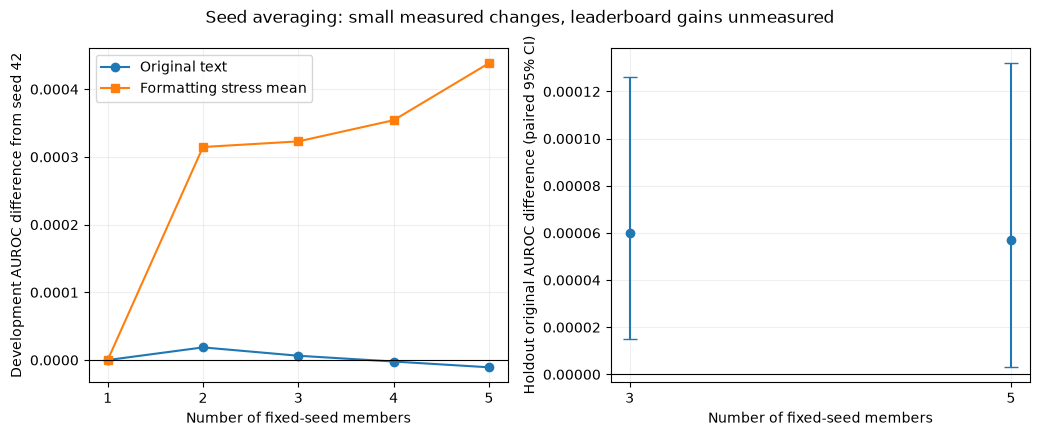

In [2]:
import matplotlib.pyplot as plt

dev_table = pd.read_csv(OUT/'development_seed_counts.csv')
held_table = pd.read_csv(OUT/'holdout_seed_counts.csv')
fig,axes = plt.subplots(1,2,figsize=(10.5,4.4))
axes[0].plot(dev_table.members,dev_table.original_delta,marker='o',label='Original text')
axes[0].plot(dev_table.members,dev_table.stress_delta,marker='s',label='Formatting stress mean')
axes[0].axhline(0,color='black',linewidth=.8)
axes[0].set_xticks([1,2,3,4,5])
axes[0].set_xlabel('Number of fixed-seed members')
axes[0].set_ylabel('Development AUROC difference from seed 42')
axes[0].legend()
base_auc = held_table.loc[held_table.members==1,'original'].iloc[0]
part = held_table[held_table.members.isin([3,5])]
delta = part.original.to_numpy()-base_auc
low = np.maximum(delta-part.delta_ci_low.to_numpy(),0)
high = np.maximum(part.delta_ci_high.to_numpy()-delta,0)
axes[1].errorbar(part.members,delta,yerr=np.vstack([low,high]),fmt='o',capsize=5)
axes[1].axhline(0,color='black',linewidth=.8)
axes[1].set_xticks([3,5])
axes[1].set_xlabel('Number of fixed-seed members')
axes[1].set_ylabel('Holdout original AUROC difference (paired 95% CI)')
for ax in axes:ax.grid(alpha=.2)
fig.suptitle('Seed averaging: small measured changes, leaderboard gains unmeasured')
fig.tight_layout()
fig.savefig(OUT/'seed_average_comparison.png',dpi=180)
plt.show()


## Final file and averaging audit

In [3]:
import subprocess

frozen = json.loads((OUT/'frozen.json').read_text())
manifest = json.loads((OUT/'submission_manifest.json').read_text())
recorded_hash = frozen.pop('recipe_sha256')
assert hashlib.sha256(json.dumps(frozen,sort_keys=True).encode()).hexdigest()==recorded_hash==manifest['recipe_sha256']
assert frozen['seed_sets']=={'seedavg_3':[42,43,44],'seedavg_5':[42,43,44,45,46]}
assert all(SPECS[n]==selected['baseline_specs'][n] for n in NAMES)
assert selected['active_blend']==frozen['active_blend']==engine['base3']['stage1_blend']
assert hashlib.sha256((ROOT/'submission_final_model_improvements.csv').read_bytes()).hexdigest()==original_summary['submission_sha256']
sample = pd.read_csv(data/'sample_submission.csv')
assert len(manifest['files'])==2
for entry in manifest['files']:
    path = ROOT/entry['file']
    assert path.resolve().is_relative_to(ROOT)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==entry['sha256']
    frame = pd.read_csv(path)
    validate_submission(frame,sample)
    components = []
    for seed in entry['members']:
        member = pd.read_csv(OUT/'test_members'/f'member_{seed}.csv').set_index('id')
        components.append(member.loc[sample.id,'original'].to_numpy())
    np.testing.assert_allclose(frame.iloc[:,1],np.mean(components,axis=0),atol=1e-12,rtol=0)
assert len(list((OUT/'submissions').glob('*.csv')))==2
assert manifest['baseline_reproduction_max_delta']<=1e-10
assert all(v<=1e-10 for v in manifest['representative_repeat_fit_max_deltas'].values())
print('Verified two 3,000-row CSVs, arithmetic averaging, exact ID order/schema, finite probabilities, hashes, frozen recipes and unchanged original parameters.')
display(pd.DataFrame(manifest['files']))
result = subprocess.run(['graphify','update','.'],cwd=ROOT,capture_output=True,text=True)
print(result.stdout)
assert result.returncode==0,result.stderr


Verified two 3,000-row CSVs, arithmetic averaging, exact ID order/schema, finite probabilities, hashes, frozen recipes and unchanged original parameters.


,name,file,members,rows,sha256
0,seedavg_3,artifacts\best_recipe_seed_average\submissions...,"[42, 43, 44]",3000,c92ddd201630dfa3f1a019cd79f879a75ff4371f124b15...
1,seedavg_5,artifacts\best_recipe_seed_average\submissions...,"[42, 43, 44, 45, 46]",3000,f686bcd32a9b490e5721a89f1c8a646eec93f5dfd4dd23...


Re-extracting code files in . (no LLM needed)...
[graphify watch] No code-graph topology changes detected; outputs left untouched.
Code graph updated. For doc/paper/image changes run /graphify --update in your AI assistant.

